# V0_pass sweep: enthalpy-only energy balance minus damping loss

This notebook runs the same acoustic-expander model for five passive-volume values from one quarter of the current value to twice the current value, then makes the zero-centered per-cycle balance plot for each case.

In [65]:
import gc
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks

# Fluid properties
gamma = 1.41
R = 287
cp = 1050
cv = 744

# Pressures (Pa). Match the V0_cv vs V0_pass heatmap setup.
P_in = 6e5
P_out = 5.45e5
P0 = 5.75e5

# Temperatures (K)
T_in = 300
T0 = T_in

# Resonator geometry
A_neck = 2.85e-4
L_neck = 0.15
m_gas = 0.0015
V0_cv = 1e-4
V0_pass_base = 3.93e-4

# Damping from Q = 60
f = 135
omega = 2 * np.pi * f
Q = 60
b_gas = 0.005

# Reed parameters
zeta = 0.6
dP = P_in - P_out
dP_max = dP / (2 * zeta)
m_max = 0.001

# Same time horizon as the heatmap cell. Increase n_eval if you need finer cycle integrals.
t_span = (0.0, 1.0)
n_eval = 20_000

# Initial conditions
x0 = 0.0
v0 = 5.0
M0_cv = P0 * V0_cv / (R * T0)
E0_cv = cv * M0_cv * T0
y0 = [x0, v0, M0_cv, E0_cv]

# Fixed V0_pass = 2e-4 m^3; sweep V0_cv from 1e-4 to 5e-4 (heatmap range).
V0_pass_fixed  = 2e-4
V0_cv_values   = np.linspace(1e-4, 5e-4, 5)
V0_pass_values = np.full_like(V0_cv_values, V0_pass_fixed)
V0_pass_factors = V0_pass_values / V0_pass_base
Pcv_collapse_threshold = 1.0e4  # Pa = 0.1 bar (kept for reference; not plotted)

start_cycle = 1


In [66]:
def reed_flow(dP, m_max_, dP_max_):
    u = dP / dP_max_
    if dP > 0 and dP < dP_max_:
        return m_max_ * (1 - u) * np.sqrt(u)
    elif dP <= 0:
        return -m_max_ * (1 - u) * np.sqrt(abs(u))
    return 0.0


def reed_flow_vec(dP, m_max_, dP_max_):
    dP = np.asarray(dP)
    u = dP / dP_max_
    out = np.zeros_like(dP, dtype=float)

    mask_open = (dP > 0) & (dP < dP_max_)
    mask_reverse = dP <= 0

    out[mask_open] = m_max_ * (1 - u[mask_open]) * np.sqrt(u[mask_open])
    out[mask_reverse] = -m_max_ * (1 - u[mask_reverse]) * np.sqrt(np.abs(u[mask_reverse]))
    return out


def acoustic_expander_ode(
    t,
    y,
    P_in_,
    P_out_,
    P0_,
    T_in_,
    T0_,
    gamma_,
    R_,
    cp_,
    cv_,
    A_neck_,
    V0_cv_,
    V0_pass_,
    m_gas_,
    b_gas_,
    m_max_,
    dP_max_,
):
    x, v, M_cv, E_cv = y

    V_cv = V0_cv_ + x * A_neck_
    T_cv = E_cv / (cv_ * M_cv) if M_cv > 0 else T0_
    P_cv = M_cv * R_ * T_cv / V_cv

    V_pass = V0_pass_ - x * A_neck_
    P_pass = P0_ * (V0_pass_ / V_pass)**gamma_ if V_pass > 0 else P0_

    dP_in = P_in_ - P_cv
    dP_out = P_cv - P_out_

    m_in = reed_flow(dP_in, m_max_, dP_max_)
    m_out = reed_flow(dP_out, m_max_, dP_max_)

    dV_cv_dt = A_neck_ * v
    dM_dt = m_in - m_out
    dE_dt = -P_cv * dV_cv_dt + m_in * cp_ * T_in_ - m_out * cp_ * T_cv

    dx_dt = v
    dv_dt = (P_cv - P_pass) * A_neck_ / m_gas_ - (b_gas_ / m_gas_) * v

    return [dx_dt, dv_dt, dM_dt, dE_dt]


def initial_state_for_parameters(P0_, V0_cv_, R_, T0_, cv_, x0_, v0_):
    M0_cv = P0_ * V0_cv_ / (R_ * T0_)
    E0_cv = cv_ * M0_cv * T0_
    return [x0_, v0_, M0_cv, E0_cv]


def simulate_for_case(V0_cv_value, V0_pass_value, t_span_=None, n_eval_=None):
    ts = t_span if t_span_ is None else t_span_
    ne = n_eval if n_eval_ is None else n_eval_
    t_eval = np.linspace(ts[0], ts[1], ne)
    y0_local = initial_state_for_parameters(P0, V0_cv_value, R, T0, cv, x0, v0)
    ode_args = (
        P_in,
        P_out,
        P0,
        T_in,
        T0,
        gamma,
        R,
        cp,
        cv,
        A_neck,
        V0_cv_value,
        V0_pass_value,
        m_gas,
        b_gas,
        m_max,
        dP_max,
    )
    sol = solve_ivp(
        acoustic_expander_ode,
        ts,
        y0_local,
        t_eval=t_eval,
        args=ode_args,
        method='RK45',
        rtol=1e-6,
        atol=1e-8,
    )
    sol.V0_cv = V0_cv_value
    sol.V0_pass = V0_pass_value
    return sol


def simulate_for_V0_pass(V0_pass_value):
    return simulate_for_case(V0_cv_sweep_value, V0_pass_value)


In [67]:
def zero_centered_limits(y, percentile=98, pad=1.15):
    y = np.asarray(y)
    finite = np.isfinite(y)
    if not np.any(finite):
        return None

    scale = np.nanpercentile(np.abs(y[finite]), percentile)
    if not np.isfinite(scale) or scale <= 0:
        scale = np.nanmax(np.abs(y[finite]))
    if not np.isfinite(scale) or scale <= 0:
        scale = 1.0

    return (-pad * scale, pad * scale)


def cycle_balance_for_solution(sol, start_cycle=1):
    t = sol.t
    x = sol.y[0]
    v = sol.y[1]
    M_cv = sol.y[2]
    E_cv = sol.y[3]

    V_cv = V0_cv + x * A_neck
    T_cv = E_cv / (cv * M_cv)
    P_cv = M_cv * R * T_cv / V_cv
    dV_cv_dt = A_neck * v

    m_in = reed_flow_vec(P_in - P_cv, m_max, dP_max)
    m_out = reed_flow_vec(P_cv - P_out, m_max, dP_max)

### here are the details of the value

    pV_power = -P_cv * dV_cv_dt
    enthalpy_in_power = m_in * cp * T_in
    enthalpy_out_power = -m_out * cp * T_cv


    dE_dt_rhs = enthalpy_in_power + enthalpy_out_power
    P_diss_damp = b_gas * v**2
### note that I kept three terms

    dt = np.median(np.diff(t))
    points_per_cycle_guess = max(3, int(round((1 / f) / dt)))
    min_peak_distance = max(1, int(0.5 * points_per_cycle_guess))

    x_for_peaks = x - np.nanmedian(x)
    finite_x = np.isfinite(x_for_peaks)
    x_span = np.nanmax(x_for_peaks[finite_x]) - np.nanmin(x_for_peaks[finite_x]) if np.any(finite_x) else 0.0
    prominence = 0.02 * x_span if x_span > 0 else None

    peak_idx, _ = find_peaks(
        x_for_peaks,
        distance=min_peak_distance,
        prominence=prominence,
    )

    if peak_idx.size < 2:
        raise ValueError('Need at least two detected displacement peaks.')

    trapz = np.trapezoid if hasattr(np, 'trapezoid') else np.trapz

    cycle_number = []
    E_balance_minus_damping = []
    P_balance_minus_damping = []

    for k, (i0, i1) in enumerate(zip(peak_idx[:-1], peak_idx[1:]), start=1):
        if k < start_cycle or i1 <= i0 + 2:
            continue

        sl = slice(i0, i1 + 1)
        period = t[i1] - t[i0]

        E_cv_no_pV = trapz(dE_dt_rhs[sl], t[sl])
        E_damp = trapz(P_diss_damp[sl], t[sl])
        E_diff = E_cv_no_pV - E_damp

        cycle_number.append(k)
        E_balance_minus_damping.append(E_diff)
        P_balance_minus_damping.append(E_diff / period)

    cycle_number = np.array(cycle_number)
    E_balance_minus_damping = np.array(E_balance_minus_damping)
    P_balance_minus_damping = np.array(P_balance_minus_damping)

    if cycle_number.size == 0:
        raise ValueError(f'No cycles found at or after cycle {start_cycle}.')

    return {
        'cycle_number': cycle_number,
        'E_balance_minus_damping': E_balance_minus_damping,
        'P_balance_minus_damping': P_balance_minus_damping,
    }


def plot_balance(result, V0_pass_value, factor, start_cycle=250):
    cycle_number = result['cycle_number']
    E_balance_minus_damping = result['E_balance_minus_damping']
    P_balance_minus_damping = result['P_balance_minus_damping']

    E_ylim = zero_centered_limits(E_balance_minus_damping)
    P_ylim = zero_centered_limits(P_balance_minus_damping)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8.2, 6.2), sharex=True)

    ax1.fill_between(
        cycle_number,
        E_balance_minus_damping,
        0.0,
        where=E_balance_minus_damping >= 0.0,
        color='tab:green',
        alpha=0.18,
        interpolate=True,
        label='above zero',
    )
    ax1.fill_between(
        cycle_number,
        E_balance_minus_damping,
        0.0,
        where=E_balance_minus_damping < 0.0,
        color='tab:red',
        alpha=0.18,
        interpolate=True,
        label='below zero',
    )
    ax1.plot(cycle_number, E_balance_minus_damping, lw=2.2, color='tab:blue')
    ax1.axhline(0.0, color='k', lw=1.0, ls='--', alpha=0.5)
    if E_ylim is not None:
        ax1.set_ylim(*E_ylim)
    ax1.set_ylabel('Energy difference per cycle (J)')
    ax1.set_title(
        f'V0_pass = {V0_pass_value:.3e} m^3 ({factor:.2g} x base)\\n'
        f'enthalpy-only dE_cv/dt minus damping loss; cycles >= {start_cycle}'
    )
    ax1.legend(fontsize=9, loc='best')
    ax1.grid(True, alpha=0.25)

    ax2.fill_between(
        cycle_number,
        P_balance_minus_damping,
        0.0,
        where=P_balance_minus_damping >= 0.0,
        color='tab:green',
        alpha=0.18,
        interpolate=True,
    )
    ax2.fill_between(
        cycle_number,
        P_balance_minus_damping,
        0.0,
        where=P_balance_minus_damping < 0.0,
        color='tab:red',
        alpha=0.18,
        interpolate=True,
    )
    ax2.plot(cycle_number, P_balance_minus_damping, lw=2.2, color='tab:red')
    ax2.axhline(0.0, color='k', lw=1.0, ls='--', alpha=0.5)
    if P_ylim is not None:
        ax2.set_ylim(*P_ylim)
    ax2.set_xlabel('Cycle number')
    ax2.set_ylabel('Average power difference (W)')
    ax2.grid(True, alpha=0.25)
    ax2.set_xlim(cycle_number[0], cycle_number[-1])

    plt.tight_layout()
    plt.show()


In [68]:
def solution_quantities(sol):
    t = sol.t
    x = sol.y[0]
    v = sol.y[1]
    M_cv = sol.y[2]
    E_cv = sol.y[3]
    V0_cv_used = getattr(sol, 'V0_cv', V0_cv)

    V_cv = V0_cv_used + x * A_neck
    T_cv = E_cv / (cv * M_cv)
    P_cv = M_cv * R * T_cv / V_cv
    dV_cv_dt = A_neck * v

    return t, x, v, M_cv, E_cv, V_cv, T_cv, P_cv, dV_cv_dt


def cumulative_trapezoid_values(t, y):
    return np.concatenate(([0.0], np.cumsum(0.5 * (y[1:] + y[:-1]) * np.diff(t))))


def integral_between(t, cumulative, t0, t1):
    return np.interp(t1, t, cumulative) - np.interp(t0, t, cumulative)


def rolling_median(y, window=31):
    y = np.asarray(y, dtype=float)
    if y.size == 0:
        return y
    window = int(window)
    if window < 3:
        return y.copy()
    if window % 2 == 0:
        window += 1
    half = window // 2
    out = np.empty_like(y)
    for i in range(y.size):
        lo = max(0, i - half)
        hi = min(y.size, i + half + 1)
        out[i] = np.nanmedian(y[lo:hi])
    return out


def upward_zero_crossing_cycles(t, x, min_period_factor=0.55, max_period_factor=1.55, baseline_periods=2.0):
    # Center on a rolling baseline (~baseline_periods oscillation periods wide) instead of
    # the global median, so crossing detection keeps tracking a slowly drifting equilibrium
    # (e.g. the reed settling to a new position) even after the oscillation amplitude has
    # shrunk well below the offset between that drift and the all-time median.
    dt = np.median(np.diff(t))
    window = max(5, int(round(baseline_periods * (1.0 / f) / dt)))
    baseline = rolling_median(x, window=window)
    x_centered = x - baseline
    finite = np.isfinite(x_centered)
    if finite.sum() < 3:
        raise ValueError('Not enough finite displacement samples for cycle detection.')

    idx = np.flatnonzero(
        finite[:-1]
        & finite[1:]
        & (x_centered[:-1] < 0.0)
        & (x_centered[1:] >= 0.0)
    )
    if idx.size < 2:
        raise ValueError('Need at least two upward zero crossings to define cycles.')

    y0 = x_centered[idx]
    y1 = x_centered[idx + 1]
    t0 = t[idx]
    t1 = t[idx + 1]
    denom = y1 - y0
    ok = np.abs(denom) > 0
    crossings = t0[ok] - y0[ok] * (t1[ok] - t0[ok]) / denom[ok]

    periods = np.diff(crossings)
    positive = periods > 0
    if not np.any(positive):
        raise ValueError('No positive cycle periods found from zero crossings.')

    period_ref = np.nanmedian(periods[positive])
    valid = positive & (periods >= min_period_factor * period_ref) & (periods <= max_period_factor * period_ref)
    cycle_numbers = np.arange(1, periods.size + 1)

    return {
        't_start': crossings[:-1][valid],
        't_end': crossings[1:][valid],
        'period': periods[valid],
        'cycle_number': cycle_numbers[valid],
        'period_ref': period_ref,
        'n_rejected': int(np.count_nonzero(~valid)),
        'n_total': int(periods.size),
    }


def cycle_balance_for_solution(sol, start_cycle=1):
    t, x, v, M_cv, E_cv, V_cv, T_cv, P_cv, dV_cv_dt = solution_quantities(sol)
    V0_pass_used = getattr(sol, 'V0_pass', np.nan)

    m_in = reed_flow_vec(P_in - P_cv, m_max, dP_max)
    m_out = reed_flow_vec(P_cv - P_out, m_max, dP_max)

    pV_power = -P_cv * dV_cv_dt
    enthalpy_in_power = m_in * cp * T_in
    enthalpy_out_power = -m_out * cp * T_cv
    # Full dE_cv/dt (matches the ODE exactly): pV work term + enthalpy flux.
    dE_dt_rhs = pV_power + enthalpy_in_power + enthalpy_out_power
    P_diss_damp = b_gas * v**2

    # Mechanical work done on piston by the net pressure force each cycle:
    # integral of (P_cv - P_pass)*A_neck*v dt.  Positive → amplitude grows.
    if np.isfinite(V0_pass_used):
        V_pass = V0_pass_used - x * A_neck
        P_pass = P0 * (V0_pass_used / V_pass) ** gamma
        mech_power = (P_cv - P_pass) * A_neck * v
    else:
        mech_power = np.full_like(v, np.nan)

    cycles = upward_zero_crossing_cycles(t, x)
    keep = cycles['cycle_number'] >= start_cycle
    if not np.any(keep):
        raise ValueError(f'No valid cycles found at or after cycle {start_cycle}.')

    cum_E    = cumulative_trapezoid_values(t, dE_dt_rhs)
    cum_damp = cumulative_trapezoid_values(t, P_diss_damp)
    cum_mech = cumulative_trapezoid_values(t, mech_power)

    cycle_number = cycles['cycle_number'][keep]
    t_start = cycles['t_start'][keep]
    t_end   = cycles['t_end'][keep]
    period  = cycles['period'][keep]

    E_cv_change = np.array([integral_between(t, cum_E,    a, b) for a, b in zip(t_start, t_end)])
    E_damp      = np.array([integral_between(t, cum_damp, a, b) for a, b in zip(t_start, t_end)])
    W_mech      = np.array([integral_between(t, cum_mech, a, b) for a, b in zip(t_start, t_end)])

    E_balance_minus_damping = E_cv_change - E_damp
    net_mech_per_cycle      = W_mech - E_damp
    P_balance_minus_damping = E_balance_minus_damping / period

    return {
        'cycle_number':            cycle_number,
        'period':                  period,
        'E_balance_minus_damping': E_balance_minus_damping,
        'net_mech_per_cycle':      net_mech_per_cycle,
        'P_balance_minus_damping': P_balance_minus_damping,
        'V0_cv':                   getattr(sol, 'V0_cv', V0_cv),
        'V0_pass':                 V0_pass_used,
        'period_ref':              cycles['period_ref'],
        'n_rejected':              cycles['n_rejected'],
        'n_total':                 cycles['n_total'],
    }


def heatmap_volume_label(V0_cv_value, V0_pass_value):
    return f'V0_cv={V0_cv_value * 1e4:.2f}, V0_pass={V0_pass_value * 1e4:.2f} (x1e-4 m^3)'


def pressure_ylim_from_percentiles(P_cv, lower=0.5, upper=99.5, pad=0.08):
    P_bar = np.asarray(P_cv, dtype=float) / 1e5
    finite = P_bar[np.isfinite(P_bar)]
    if finite.size == 0:
        return None
    lo, hi = np.nanpercentile(finite, [lower, upper])
    if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
        return None
    span = hi - lo
    return max(0.0, lo - pad * span), hi + pad * span


def plot_pressure_time(sol, V0_pass_value, factor, max_points=40_000):
    t, x, v, M_cv, E_cv, V_cv, T_cv, P_cv, dV_cv_dt = solution_quantities(sol)
    V0_cv_used = getattr(sol, 'V0_cv', V0_cv)
    V0_pass_used = getattr(sol, 'V0_pass', V0_pass_value)
    stride = max(1, int(np.ceil(t.size / max_points)))
    P_ylim = pressure_ylim_from_percentiles(P_cv)

    fig, ax1 = plt.subplots(figsize=(8.2, 3.2))
    ax1.plot(t[::stride], P_cv[::stride] / 1e5, lw=0.8, color='tab:blue')
    ax1.axhline(P_in / 1e5, color='k', lw=1.0, ls='--', alpha=0.45, label='P_in')
    ax1.axhline(P_out / 1e5, color='k', lw=1.0, ls=':', alpha=0.45, label='P_out')
    if P_ylim is not None:
        ax1.set_ylim(*P_ylim)
    ax1.set_xlabel('Time (s)')
    ax1.set_ylabel(r'$P_{cv}$ (bar)')
    ax1.set_title(r'$P_{cv}$, ' + heatmap_volume_label(V0_cv_used, V0_pass_used))
    ax1.legend(fontsize=9, loc='best')
    ax1.grid(True, alpha=0.25)

    plt.tight_layout()
    plt.show()


def cycle_amplitudes(sol, start_cycle=1):
    # Per-cycle oscillation amplitude = half peak-to-peak of the displacement x,
    # measured over each cycle window found by upward_zero_crossing_cycles (the same
    # oscillation extractor used for the energy balance).
    t = sol.t
    x = sol.y[0]
    cycles = upward_zero_crossing_cycles(t, x)
    keep = cycles['cycle_number'] >= start_cycle
    cycle_number = cycles['cycle_number'][keep]
    t_start = cycles['t_start'][keep]
    t_end = cycles['t_end'][keep]

    amplitude = np.full(cycle_number.size, np.nan)
    for i, (a, b) in enumerate(zip(t_start, t_end)):
        seg = x[(t >= a) & (t <= b)]
        seg = seg[np.isfinite(seg)]
        if seg.size:
            amplitude[i] = 0.5 * (np.nanmax(seg) - np.nanmin(seg))
    return cycle_number, amplitude


def plot_amplitude(sol, V0_pass_value, factor, start_cycle=1):
    V0_cv_used = getattr(sol, 'V0_cv', V0_cv)
    V0_pass_used = getattr(sol, 'V0_pass', V0_pass_value)
    cycle_number, amplitude = cycle_amplitudes(sol, start_cycle=start_cycle)

    fig, ax = plt.subplots(figsize=(8.2, 3.6))
    ax.plot(cycle_number, amplitude * 1e3, lw=1.8, color='tab:purple')
    ax.set_xlabel('Cycle number')
    ax.set_ylabel('Oscillation amplitude (mm)')
    ax.set_title(
        'Oscillation amplitude (half peak-to-peak of x)  |  '
        + heatmap_volume_label(V0_cv_used, V0_pass_used)
    )
    ax.grid(True, alpha=0.25)
    if cycle_number.size:
        ax.set_xlim(cycle_number[0], cycle_number[-1])

    plt.tight_layout()
    plt.show()


def cycle_energy_amplitude(sol, start_cycle=1):
    # Aligned per-cycle (cycle_number, net_mech_per_cycle, amplitude) for one solution.
    # Both come from the same upward-zero-crossing extraction, so they line up cycle-for-cycle.
    bal = cycle_balance_for_solution(sol, start_cycle=start_cycle)
    cyc_A, A = cycle_amplitudes(sol, start_cycle=start_cycle)
    bn = bal['cycle_number']
    net = bal['net_mech_per_cycle']
    common = np.intersect1d(cyc_A, bn)
    A_c = A[np.isin(cyc_A, common)]
    net_c = net[np.isin(bn, common)]
    return common, net_c, A_c


def plot_energy_vs_dA2(sol, V0_pass_value, factor, start_cycle=1):
    # Quantitative proof: net energy added per cycle vs change in A^2 is a straight
    # line through the origin, and its slope recovers the oscillator stiffness k_eff.
    V0_cv_used = getattr(sol, 'V0_cv', V0_cv)
    V0_pass_used = getattr(sol, 'V0_pass', V0_pass_value)
    n, net, A = cycle_energy_amplitude(sol, start_cycle=start_cycle)
    dA2 = np.diff(A ** 2)
    net_pair = net[:-1]
    n_pair = n[:-1]
    good = np.isfinite(dA2) & np.isfinite(net_pair)
    dA2, net_pair, n_pair = dA2[good], net_pair[good], n_pair[good]
    if dA2.size < 3 or np.allclose(dA2, 0.0):
        print('Not enough varying cycles to fit net energy vs change in A^2.')
        return

    slope = np.sum(net_pair * dA2) / np.sum(dA2 * dA2)          # slope = k_eff / 2
    resid = net_pair - slope * dA2
    ss_tot = np.sum((net_pair - net_pair.mean()) ** 2)
    R2 = 1.0 - np.sum(resid ** 2) / ss_tot if ss_tot > 0 else float('nan')
    k_emp = 2.0 * slope
    k_ana = gamma * A_neck ** 2 * P0 * (1.0 / V0_cv_used + 1.0 / V0_pass_used)

    fig, ax = plt.subplots(figsize=(6.4, 5.0))
    sc = ax.scatter(dA2 * 1e6, net_pair * 1e3, c=n_pair, cmap='viridis', s=14)
    xs = np.linspace(dA2.min(), dA2.max(), 50)
    ax.plot(xs * 1e6, slope * xs * 1e3, 'r-', lw=2,
            label=f'net = (k/2) d(A^2), through 0\nk_eff(fit)={k_emp:.0f} N/m\nk_eff(analytic)={k_ana:.0f} N/m\nR^2={R2:.3f}')
    ax.axhline(0.0, color='k', lw=0.8, ls='--', alpha=0.5)
    ax.axvline(0.0, color='k', lw=0.8, ls='--', alpha=0.5)
    ax.set_xlabel(r'$\Delta(A^2)$ per cycle  (mm$^2$)')
    ax.set_ylabel('net energy added per cycle (mJ)')
    ax.set_title('Net work $-$ damping $=$ change in oscillator energy $\\frac{1}{2}kA^2$\n'
                 + heatmap_volume_label(V0_cv_used, V0_pass_used))
    cb = plt.colorbar(sc)
    cb.set_label('cycle number')
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


def plot_net_and_amplitude(sol, V0_pass_value, factor, start_cycle=1, smooth_window=15):
    # Timing check: amplitude rises exactly while net energy per cycle is positive,
    # and plateaus (limit cycle) as net -> 0.
    V0_cv_used = getattr(sol, 'V0_cv', V0_cv)
    V0_pass_used = getattr(sol, 'V0_pass', V0_pass_value)
    n, net, A = cycle_energy_amplitude(sol, start_cycle=start_cycle)
    net_s = rolling_median(net, window=smooth_window)

    fig, ax = plt.subplots(figsize=(7.6, 4.2))
    ax.fill_between(n, net_s * 1e3, 0.0, where=net_s >= 0, color='tab:green',
                    alpha=0.25, interpolate=True, label='net > 0 (energy in)')
    ax.fill_between(n, net_s * 1e3, 0.0, where=net_s < 0, color='tab:red',
                    alpha=0.25, interpolate=True, label='net < 0 (energy out)')
    ax.plot(n, net_s * 1e3, color='k', lw=1.6)
    ax.axhline(0.0, color='k', lw=0.8, ls='--')
    ax.set_xlabel('cycle number')
    ax.set_ylabel('net energy per cycle (mJ)')

    ax2 = ax.twinx()
    ax2.plot(n, A * 1e3, color='tab:purple', lw=2.2)
    ax2.set_ylabel('oscillation amplitude (mm)', color='tab:purple')
    ax2.tick_params(axis='y', colors='tab:purple')

    ax.set_title('Amplitude rises while net > 0, flat as net -> 0  |  '
                 + heatmap_volume_label(V0_cv_used, V0_pass_used))
    ax.legend(loc='center right', fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_balance(result, V0_pass_value, factor, start_cycle=1, smooth_window=31):
    cycle_number            = result['cycle_number']
    E_balance_minus_damping = result['E_balance_minus_damping']
    net_mech_per_cycle      = result.get('net_mech_per_cycle')
    V0_cv_value             = result.get('V0_cv', V0_cv)
    V0_pass_value           = result.get('V0_pass', V0_pass_value)

    has_mech = net_mech_per_cycle is not None and np.any(np.isfinite(net_mech_per_cycle))
    nrows = 2 if has_mech else 1
    fig, axes = plt.subplots(nrows, 1, figsize=(8.2, 3.8 + 3.6 * (nrows - 1)), sharex=True)
    if nrows == 1:
        axes = [axes]

    # --- top panel: full dE_cv/dt (incl. pV) minus damping ---
    ax1 = axes[0]
    E_trend = rolling_median(E_balance_minus_damping, window=smooth_window)
    E_ylim  = zero_centered_limits(E_balance_minus_damping, percentile=99.0)
    sign_E  = np.where(E_balance_minus_damping >= 0.0, 'tab:green', 'tab:red')

    ax1.scatter(cycle_number, E_balance_minus_damping, s=8, c=sign_E, alpha=0.28, linewidths=0, label='cycles')
    ax1.plot(cycle_number, E_trend, lw=2.4, color='k', label=f'{smooth_window}-cycle median')
    ax1.axhline(0.0, color='k', lw=1.0, ls='--', alpha=0.55)
    if E_ylim is not None:
        ax1.set_ylim(*E_ylim)
    ax1.set_ylabel('Energy per cycle (J)')
    ax1.set_title(
        r'$\Delta E_{cv}$ (incl. $-P_{cv}\dot{V}$) $-$ damping  |  '
        + heatmap_volume_label(V0_cv_value, V0_pass_value)
    )
    ax1.legend(fontsize=9, loc='best')
    ax1.grid(True, alpha=0.25)
    ax1.set_xlim(cycle_number[0], cycle_number[-1])

    # --- bottom panel: mechanical work minus damping ---
    if has_mech:
        ax2 = axes[1]
        M_trend = rolling_median(net_mech_per_cycle, window=smooth_window)
        M_ylim  = zero_centered_limits(net_mech_per_cycle, percentile=99.0)
        sign_M  = np.where(net_mech_per_cycle >= 0.0, 'tab:green', 'tab:red')

        ax2.scatter(cycle_number, net_mech_per_cycle, s=8, c=sign_M, alpha=0.28, linewidths=0, label='cycles')
        ax2.plot(cycle_number, M_trend, lw=2.4, color='k', label=f'{smooth_window}-cycle median')
        ax2.axhline(0.0, color='k', lw=1.0, ls='--', alpha=0.55)
        if M_ylim is not None:
            ax2.set_ylim(*M_ylim)
        ax2.set_xlabel('Cycle number')
        ax2.set_ylabel('Net mech. energy per cycle (J)')
        ax2.set_title(r'$\oint(P_{cv}-P_{pass})A_{neck}v\,dt$ $-$ damping  (>0 → grows, <0 → decays)')
        ax2.legend(fontsize=9, loc='best')
        ax2.grid(True, alpha=0.25)
    else:
        axes[-1].set_xlabel('Cycle number')

    plt.tight_layout()
    plt.show()


Running V0_cv=1.00, V0_pass=2.00 (x1e-4 m^3)


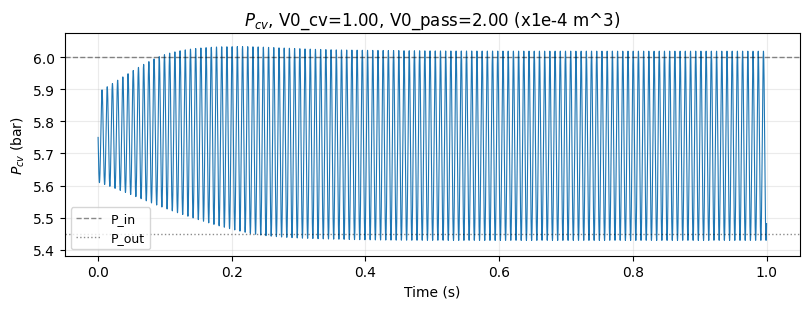

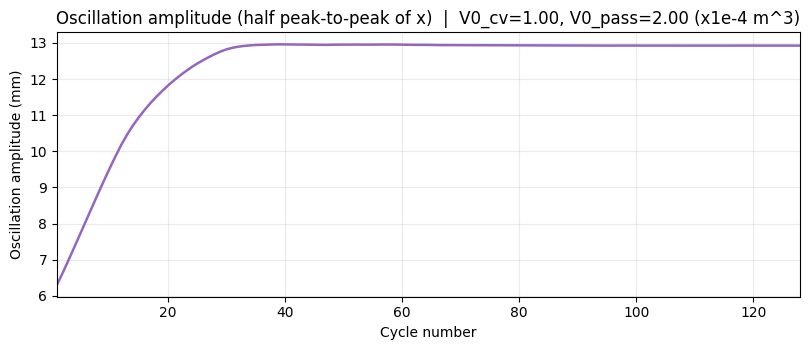

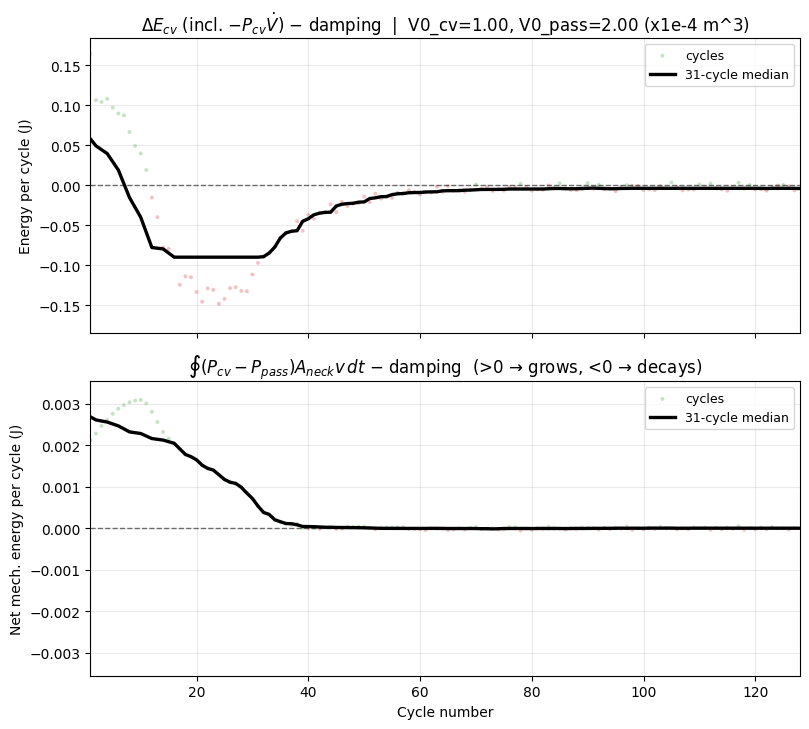

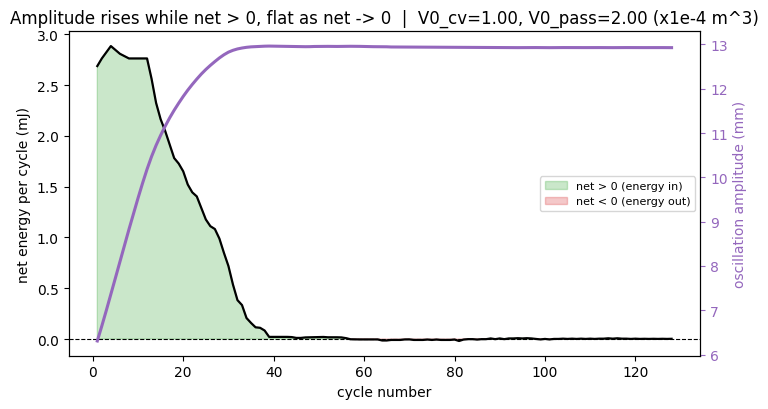

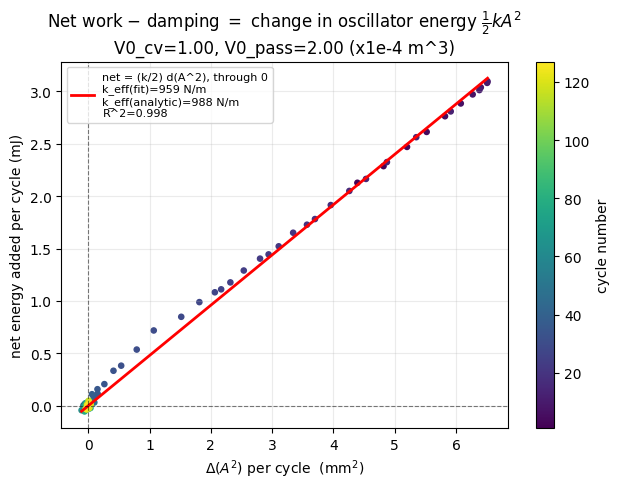

Running V0_cv=2.00, V0_pass=2.00 (x1e-4 m^3)


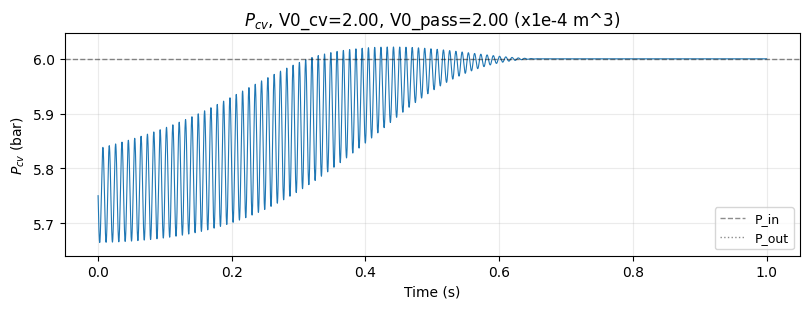

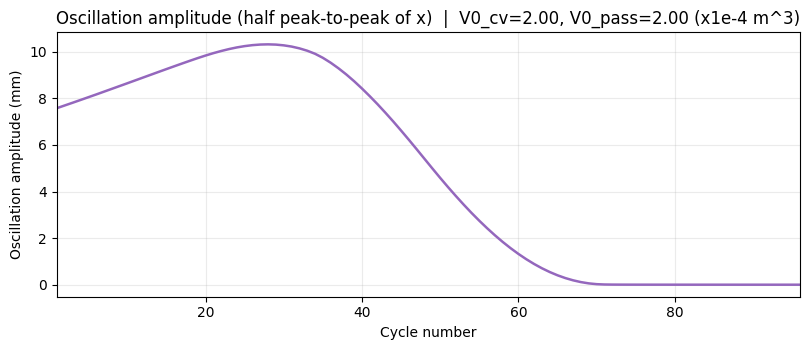

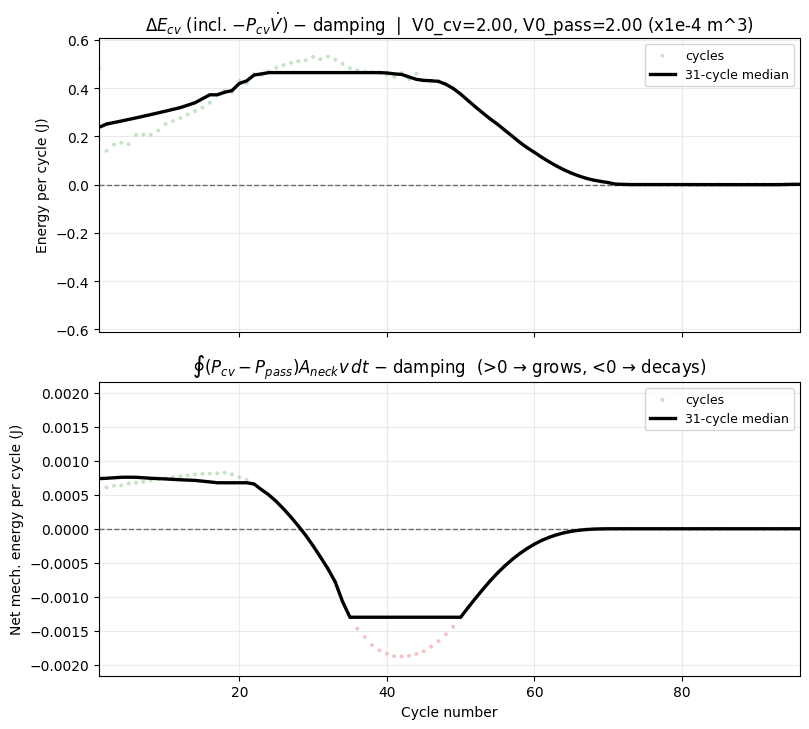

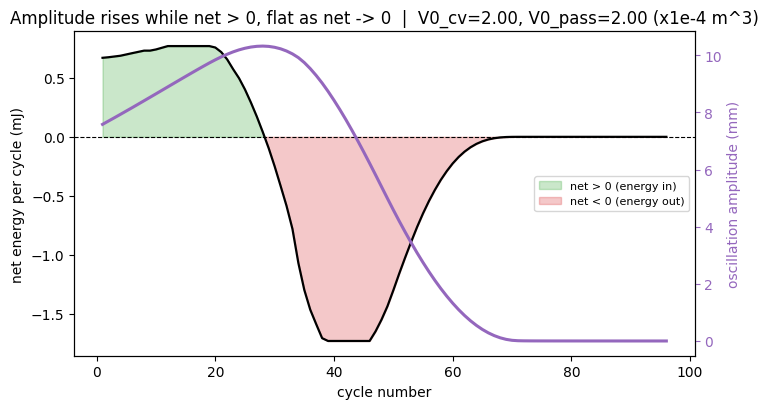

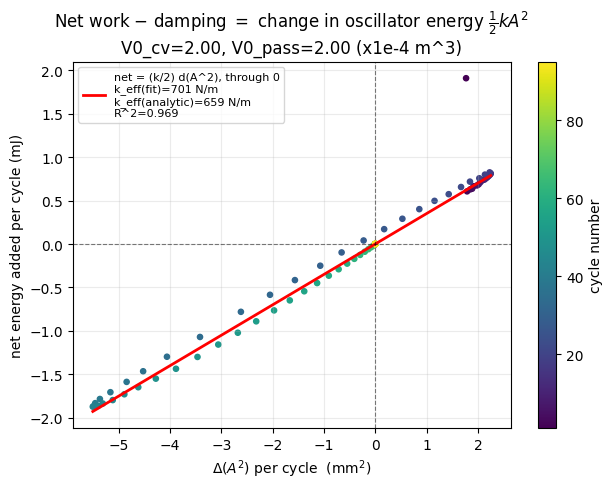

Running V0_cv=3.00, V0_pass=2.00 (x1e-4 m^3)


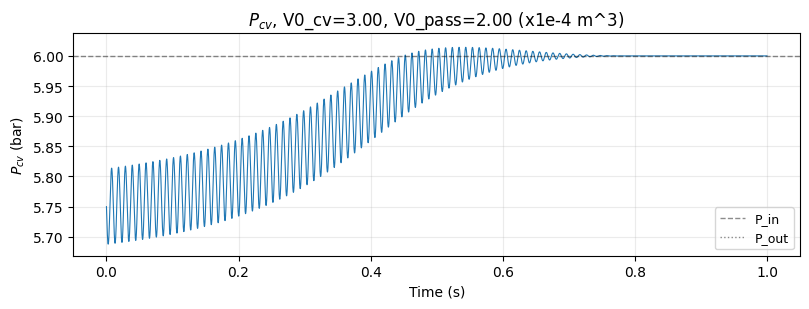

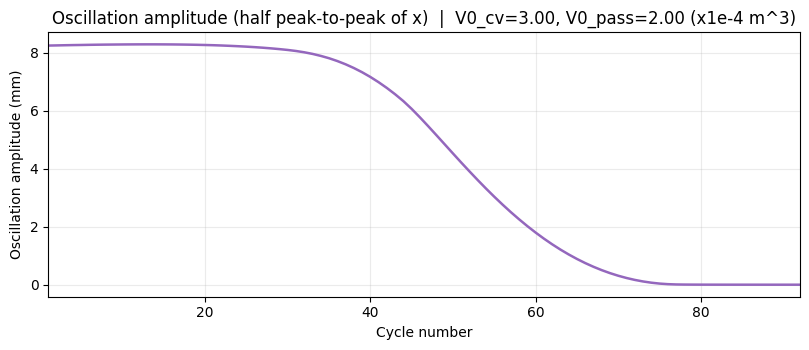

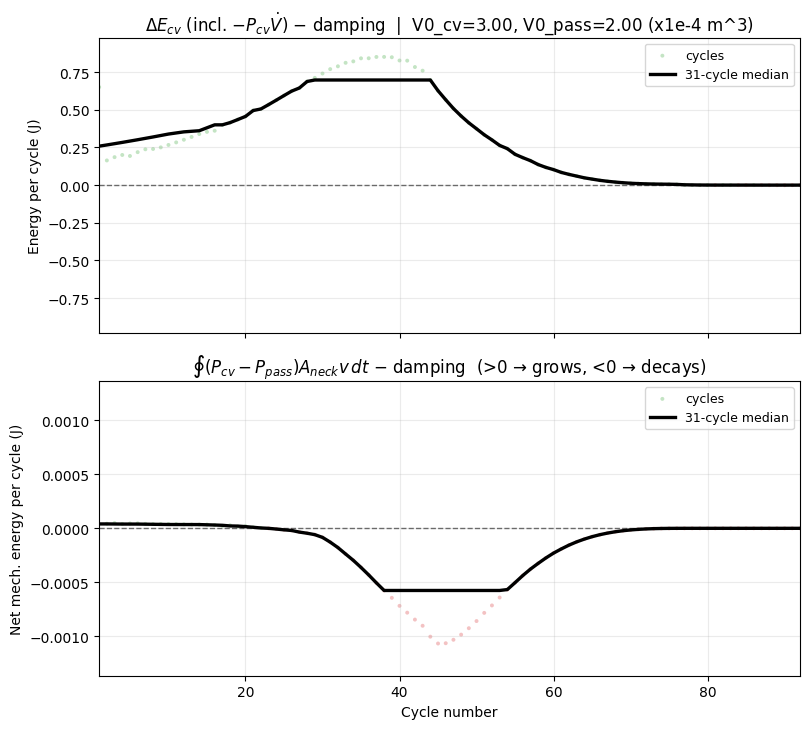

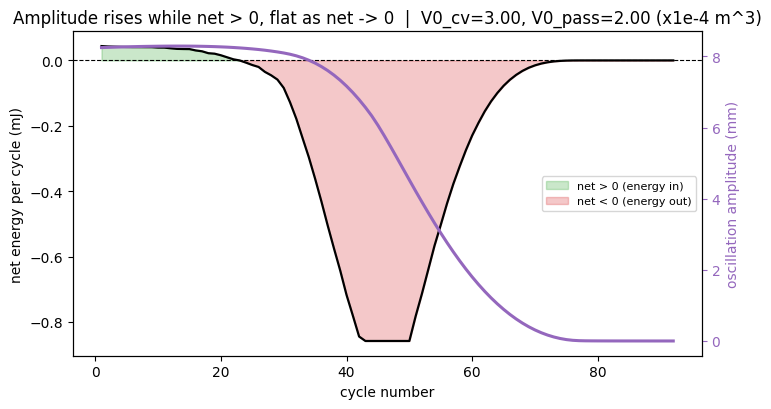

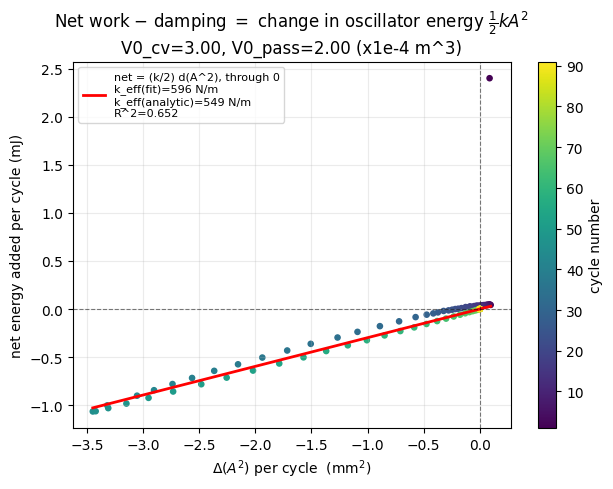

Running V0_cv=4.00, V0_pass=2.00 (x1e-4 m^3)


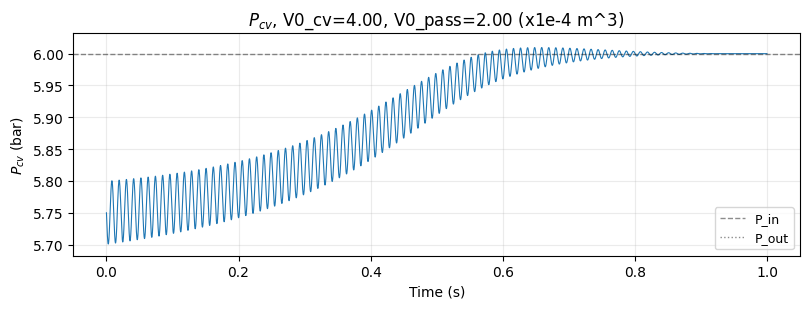

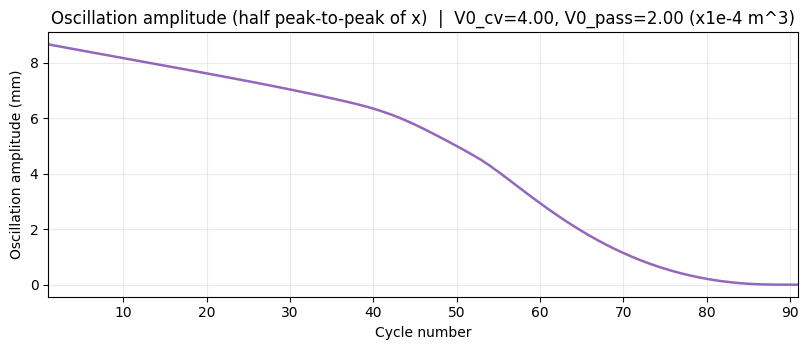

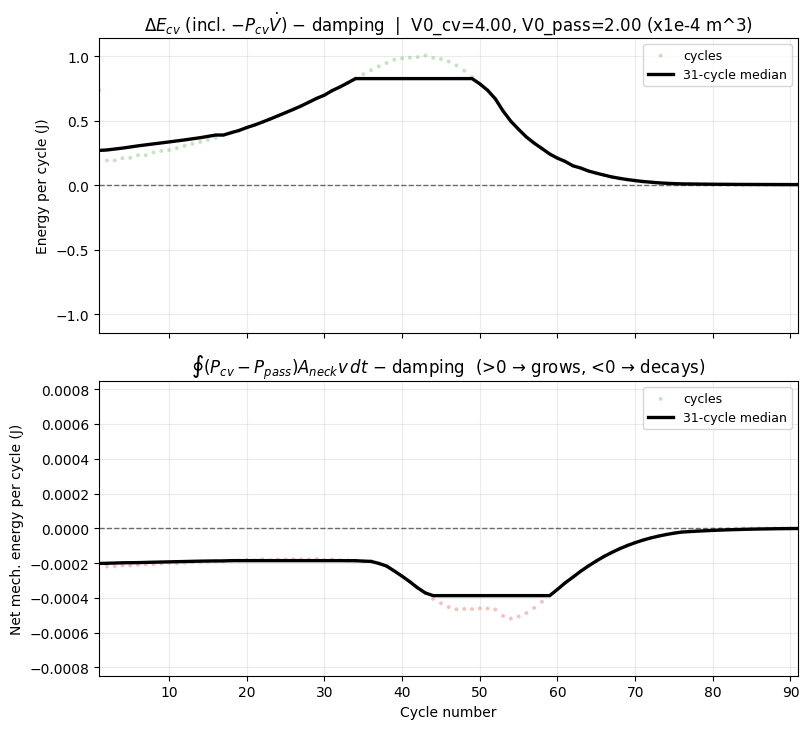

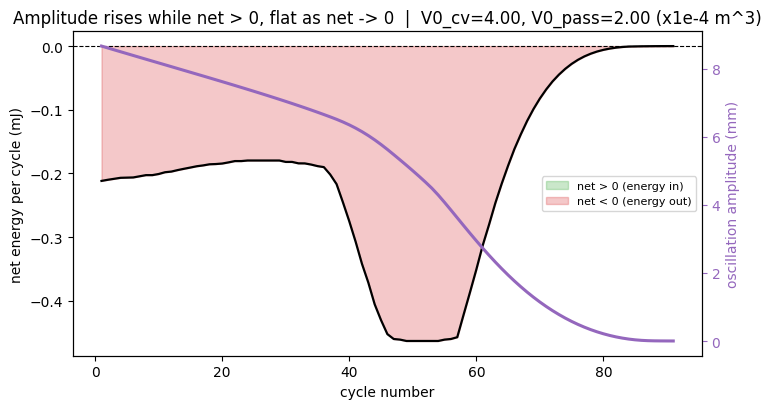

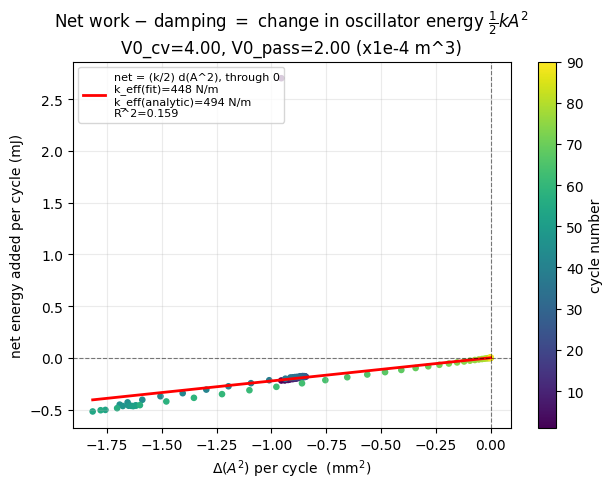

Running V0_cv=5.00, V0_pass=2.00 (x1e-4 m^3)


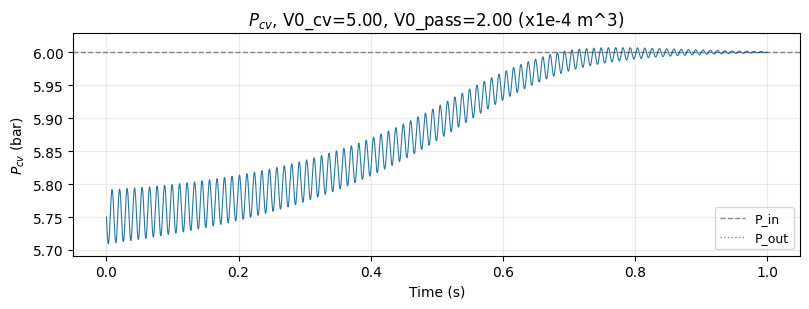

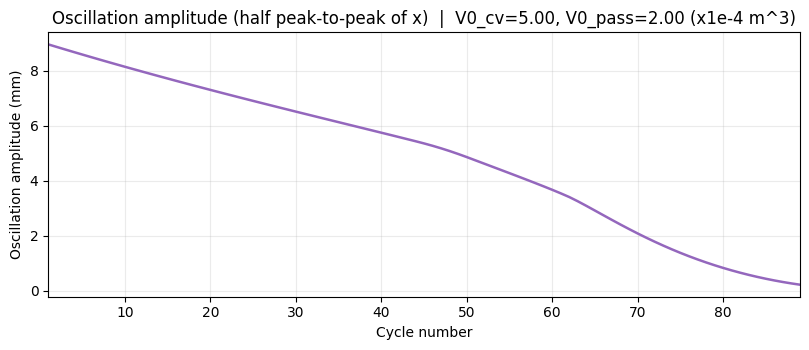

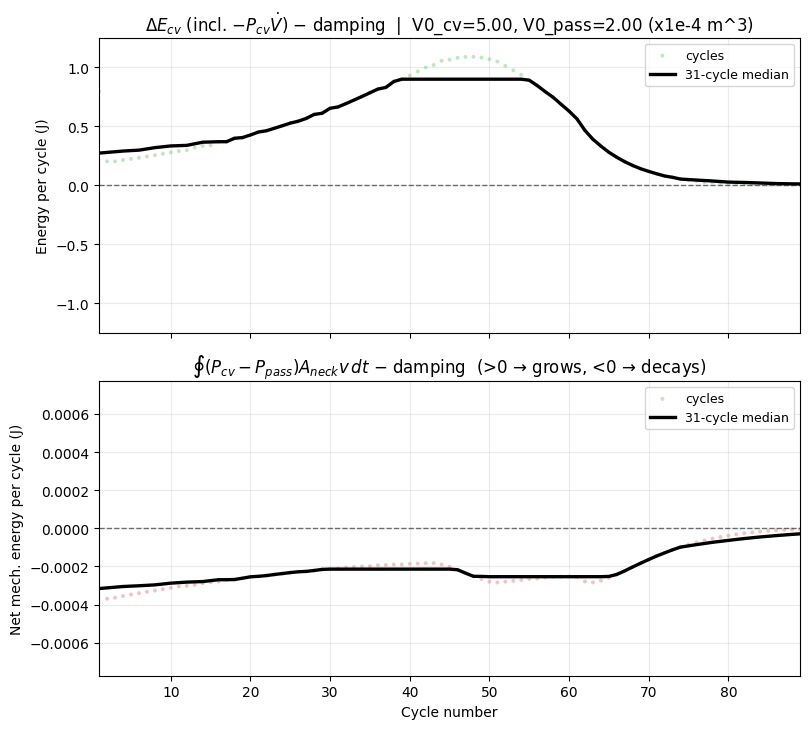

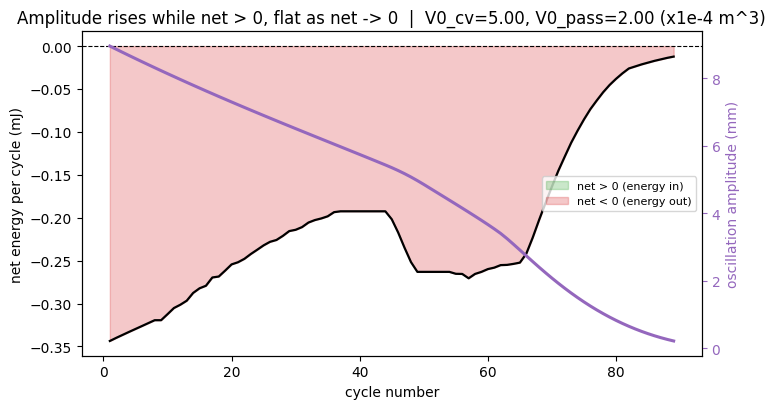

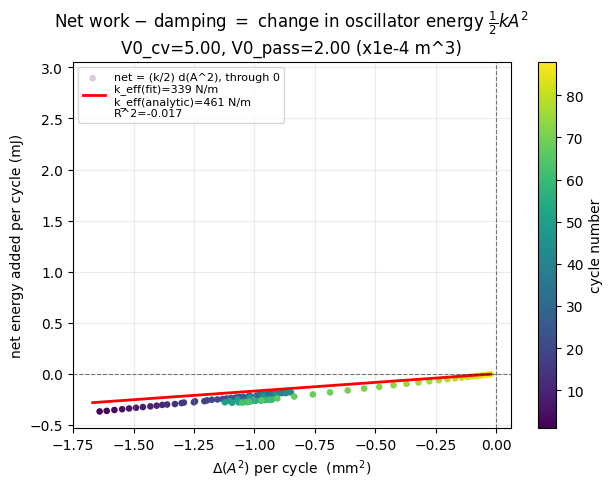

In [69]:
for V0_cv_value, V0_pass_value, factor in zip(V0_cv_values, V0_pass_values, V0_pass_factors):
    print('Running ' + heatmap_volume_label(V0_cv_value, V0_pass_value))
    sol_i = simulate_for_case(V0_cv_value, V0_pass_value)
    plot_pressure_time(sol_i, V0_pass_value, factor)
    plot_amplitude(sol_i, V0_pass_value, factor, start_cycle=start_cycle)
    balance_i = cycle_balance_for_solution(sol_i, start_cycle=start_cycle)
    plot_balance(balance_i, V0_pass_value, factor, start_cycle=start_cycle)
    plot_net_and_amplitude(sol_i, V0_pass_value, factor, start_cycle=start_cycle)
    plot_energy_vs_dA2(sol_i, V0_pass_value, factor, start_cycle=start_cycle)
    del sol_i, balance_i
    gc.collect()


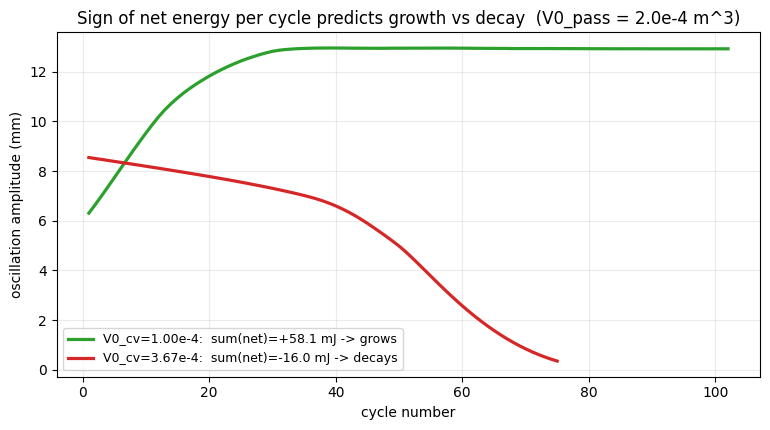

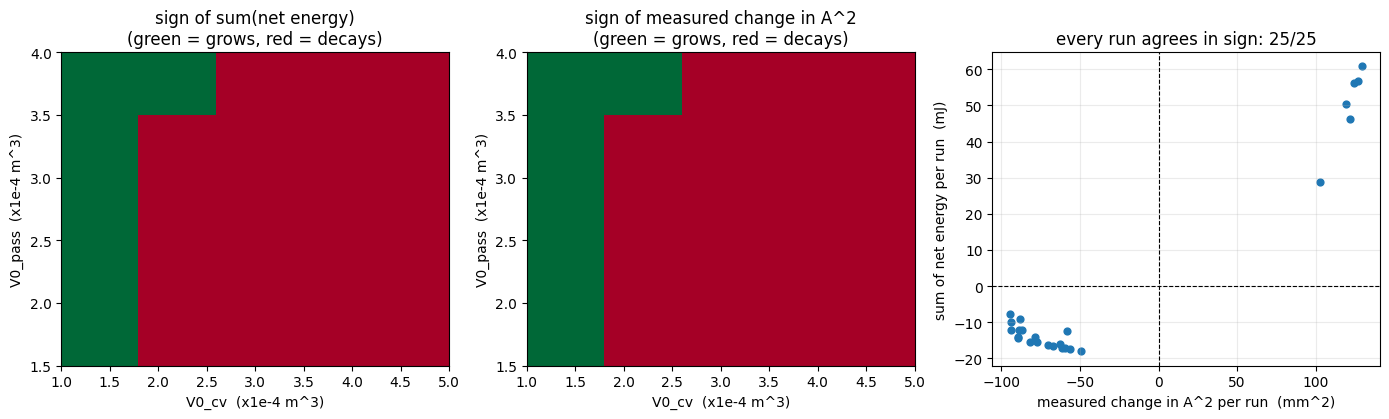

In [70]:
# ===========================================================================
# Cross-case evidence that net_mech_per_cycle drives the amplitude:
#   (1) a growing case and a decaying case on the same amplitude axes
#   (2) sign agreement across a V0_cv x V0_pass grid + cross-case linearity
# Modest time/resolution keeps the grid quick; raise for final figures.
# ===========================================================================
SWEEP_T_SPAN = (0.0, 0.8)
SWEEP_N_EVAL = 12_000


def case_net_and_amplitude(V0_cv_value, V0_pass_value, start_cycle=1):
    sol = simulate_for_case(V0_cv_value, V0_pass_value, SWEEP_T_SPAN, SWEEP_N_EVAL)
    n, net, A = cycle_energy_amplitude(sol, start_cycle=start_cycle)
    del sol
    gc.collect()
    return n, net, A


# ---- (1) growing vs decaying, same axes ----
contrast_cases = [
    (1.0e-4, 2.0e-4, 'tab:green'),
    (3.67e-4, 2.0e-4, 'tab:red'),
]
fig, ax = plt.subplots(figsize=(7.8, 4.4))
for V0_cv_value, V0_pass_value, color in contrast_cases:
    n, net, A = case_net_and_amplitude(V0_cv_value, V0_pass_value)
    sum_net = np.nansum(net)
    verdict = 'grows' if sum_net > 0 else 'decays'
    ax.plot(n, A * 1e3, lw=2.3, color=color,
            label=f'V0_cv={V0_cv_value * 1e4:.2f}e-4:  sum(net)={sum_net * 1e3:+.1f} mJ -> {verdict}')
ax.set_xlabel('cycle number')
ax.set_ylabel('oscillation amplitude (mm)')
ax.set_title('Sign of net energy per cycle predicts growth vs decay  (V0_pass = 2.0e-4 m^3)')
ax.legend(fontsize=9)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# ---- (2) sign agreement across the V0_cv x V0_pass grid ----
cv_grid = np.linspace(1e-4, 5e-4, 5)
vp_grid = np.linspace(1.5e-4, 4.0e-4, 5)
sum_net_mat = np.full((vp_grid.size, cv_grid.size), np.nan)
dA2_mat = np.full_like(sum_net_mat, np.nan)
for j, vp in enumerate(vp_grid):
    for i, vc in enumerate(cv_grid):
        try:
            n, net, A = case_net_and_amplitude(vc, vp)
            sum_net_mat[j, i] = np.nansum(net)
            dA2_mat[j, i] = A[-1] ** 2 - A[0] ** 2
        except Exception as exc:
            print(f'  skip V0_cv={vc:.2e}, V0_pass={vp:.2e}: {exc}')

finite = np.isfinite(sum_net_mat) & np.isfinite(dA2_mat)
agree = np.sign(sum_net_mat[finite]) == np.sign(dA2_mat[finite])
extent = [cv_grid[0] * 1e4, cv_grid[-1] * 1e4, vp_grid[0] * 1e4, vp_grid[-1] * 1e4]

fig, axes = plt.subplots(1, 3, figsize=(14.0, 4.3))
for ax, M, title in [(axes[0], np.sign(sum_net_mat), 'sign of sum(net energy)'),
                     (axes[1], np.sign(dA2_mat), 'sign of measured change in A^2')]:
    ax.imshow(M, origin='lower', extent=extent, aspect='auto', cmap='RdYlGn', vmin=-1, vmax=1)
    ax.set_xlabel('V0_cv  (x1e-4 m^3)')
    ax.set_ylabel('V0_pass  (x1e-4 m^3)')
    ax.set_title(title + '\n(green = grows, red = decays)')

ax = axes[2]
xx = dA2_mat[finite] * 1e6
yy = sum_net_mat[finite] * 1e3
ax.scatter(xx, yy, c='tab:blue', s=24)
ax.axhline(0.0, color='k', lw=0.8, ls='--')
ax.axvline(0.0, color='k', lw=0.8, ls='--')
ax.set_xlabel('measured change in A^2 per run  (mm^2)')
ax.set_ylabel('sum of net energy per run  (mJ)')
ax.set_title(f'every run agrees in sign: {int(agree.sum())}/{agree.size}')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## Why a larger passive volume lets the amplitude grow

The passive gas is the **return spring**, with stiffness
$$k_{\text{pass}}=\frac{\gamma P_0 A_{\text{neck}}^2}{V_{0,\text{pass}}},\qquad
k_{\text{eff}}=\gamma P_0 A_{\text{neck}}^2\!\left(\tfrac{1}{V_{0,cv}}+\tfrac{1}{V_{0,\text{pass}}}\right),\qquad
\omega=\sqrt{k_{\text{eff}}/m_{\text{gas}}}.$$
A larger $V_{0,\text{pass}}$ **softens** this spring ($k_{\text{pass}}\downarrow$) and lowers the frequency $\omega$. Two complementary consequences:

**1. Energy / initial amplitude.** The kick $v_0$ injects a fixed energy $E_0=\tfrac12 m_{\text{gas}}v_0^2$ (since $x_0=0$), which converts to amplitude
$$E_0=\tfrac12 k_{\text{eff}}A_0^2\;\Rightarrow\; A_0=v_0\sqrt{m_{\text{gas}}/k_{\text{eff}}}=v_0/\omega.$$
Smaller $k_{\text{eff}}$ &rArr; the same energy produces a **larger initial swing** $A_0$ (confirmed below: $A_0=v_0/\omega$ matches the measured first cycle).

**2. Sustaining / limit cycle.** Each cycle $\;\Delta E = W_{\text{drive}}-W_{\text{damp}}\;$ with
$$W_{\text{damp}}=\oint b_{\text{gas}}\dot{x}^2\,dt=\pi b_{\text{gas}}\,\omega\,A^2\;\propto\;\omega.$$
Lower $\omega$ &rArr; at a given amplitude the **damping loss per cycle is smaller**, so the reed's input more easily beats it and the stable limit cycle $A^{*}$ (where $W_{\text{drive}}(A^{*})=W_{\text{damp}}(A^{*})$) shifts to a **higher amplitude**.

Together a softer passive spring both **starts** the oscillation bigger ($A_0\uparrow$) and lets it **sustain** bigger ($A^{*}\uparrow$). Expect an optimum: too soft eventually detunes the reed phasing.


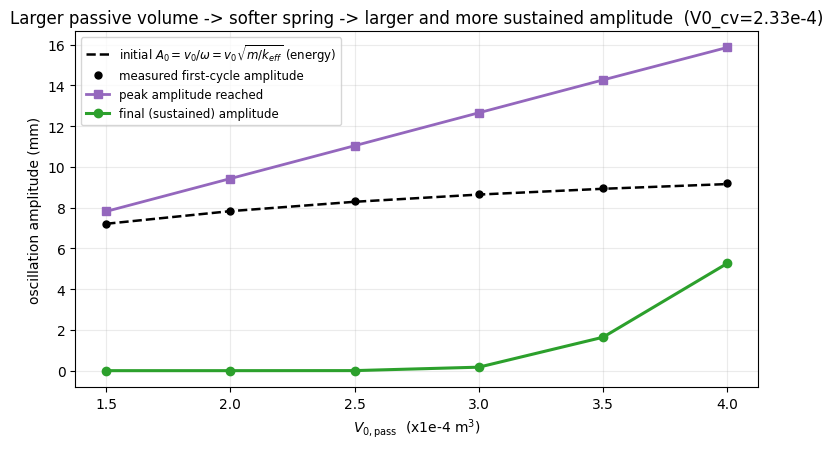

In [71]:
# Amplitude vs passive volume: the energy argument (initial A0) and the
# sustaining argument (final A*) together. Fixed V0_cv, sweep V0_pass.
AMP_T_SPAN = (0.0, 0.8)
AMP_N_EVAL = 12_000


def amplitude_vs_V0pass(V0_cv_value, V0_pass_values):
    A0_pred = np.empty(V0_pass_values.size)   # v0/omega from the energy argument
    A_first = np.empty(V0_pass_values.size)
    A_max = np.empty(V0_pass_values.size)
    A_final = np.empty(V0_pass_values.size)
    for i, Vp in enumerate(V0_pass_values):
        keff = gamma * P0 * A_neck ** 2 * (1.0 / V0_cv_value + 1.0 / Vp)
        A0_pred[i] = v0 / np.sqrt(keff / m_gas)
        sol = simulate_for_case(V0_cv_value, Vp, AMP_T_SPAN, AMP_N_EVAL)
        cn, A = cycle_amplitudes(sol, start_cycle=1)
        A_first[i] = A[0]
        A_max[i] = np.nanmax(A)
        A_final[i] = A[-1]
        del sol
        gc.collect()
    return A0_pred, A_first, A_max, A_final


V0_cv_fixed = 2.33e-4
V0_pass_scan = np.linspace(1.5e-4, 4.0e-4, 6)
A0_pred, A_first, A_max, A_final = amplitude_vs_V0pass(V0_cv_fixed, V0_pass_scan)

vp = V0_pass_scan * 1e4
fig, ax = plt.subplots(figsize=(7.6, 4.6))
ax.plot(vp, A0_pred * 1e3, 'k--', lw=1.8, label=r'initial $A_0=v_0/\omega=v_0\sqrt{m/k_{eff}}$ (energy)')
ax.plot(vp, A_first * 1e3, 'ko', ms=5, label='measured first-cycle amplitude')
ax.plot(vp, A_max * 1e3, 's-', color='tab:purple', lw=2, label='peak amplitude reached')
ax.plot(vp, A_final * 1e3, 'o-', color='tab:green', lw=2.2, label='final (sustained) amplitude')
ax.set_xlabel(r'$V_{0,\mathrm{pass}}$  (x1e-4 m$^3$)')
ax.set_ylabel('oscillation amplitude (mm)')
ax.set_title('Larger passive volume -> softer spring -> larger and more sustained amplitude'
             f'  (V0_cv={V0_cv_fixed * 1e4:.2f}e-4)')
ax.legend(fontsize=8.5)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## Drive vs damping curves (the limit-cycle picture)

Per cycle the reed adds $W_{\text{drive}}=\oint (P_{cv}-P_{\text{pass}})A_{\text{neck}}\dot{x}\,dt$ and damping removes
$W_{\text{damp}}=\pi b_{\text{gas}}\,\omega\,A^{2}$. Plotted against amplitude:

- where the **drive curve sits above the damping curve**, $\Delta E>0$ and the amplitude **grows**;
- they cross at the **stable limit cycle** $A^{*}$ (marked dot), where $W_{\text{drive}}=W_{\text{damp}}$ and the amplitude holds steady;
- a larger $V_{0,\text{pass}}$ lowers $\omega$, giving a **shallower damping parabola** (less loss per cycle at a given $A$).

Shown in the clean growing regime ($V_{0,cv}=1.0\times10^{-4}$). In the marginal regime the startup transient overshoots, so the per-cycle curves become multivalued and noisy &mdash; there the amplitude-vs-$V_{0,\text{pass}}$ summary above is the better view.


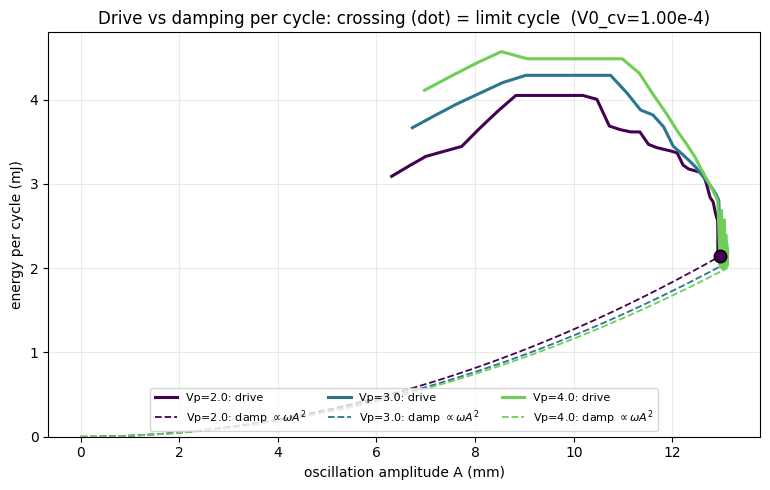

In [72]:
# Drive vs damping per cycle, as a function of amplitude. Their crossing is the
# stable limit cycle A* (where W_drive = W_damp). Drive above damping -> the
# amplitude grows toward A*; a larger V0_pass lowers omega, giving a shallower
# damping parabola W_damp = pi*b_gas*omega*A^2.
def plot_drive_damp_curves(V0_cv_value, V0_pass_values, t_span=(0.0, 0.8), n_eval=12_000, smooth=9):
    fig, ax = plt.subplots(figsize=(7.8, 5.0))
    colors = plt.cm.viridis(np.linspace(0, 0.78, len(V0_pass_values)))
    for color, Vp in zip(colors, V0_pass_values):
        sol = simulate_for_case(V0_cv_value, Vp, t_span, n_eval)
        t, x, v, M_cv, E_cv, V_cv, T_cv, P_cv, dV = solution_quantities(sol)
        P_pass = P0 * (Vp / (Vp - x * A_neck)) ** gamma
        drive_power = (P_cv - P_pass) * A_neck * v
        cycles = upward_zero_crossing_cycles(t, x)
        A = []
        W_drive = []
        for a, b in zip(cycles['t_start'], cycles['t_end']):
            m = (t >= a) & (t <= b)
            if m.sum() < 3:
                continue
            A.append(0.5 * (np.nanmax(x[m]) - np.nanmin(x[m])))
            W_drive.append(np.trapezoid(drive_power[m], t[m]))
        A = np.array(A)
        W_drive = rolling_median(np.array(W_drive), window=smooth)
        order = np.argsort(A)

        keff = gamma * P0 * A_neck ** 2 * (1.0 / V0_cv_value + 1.0 / Vp)
        omega = np.sqrt(keff / m_gas)
        A_line = np.linspace(0.0, A.max(), 120)
        W_damp = np.pi * b_gas * omega * A_line ** 2

        lab = f'{Vp * 1e4:.1f}'
        ax.plot(A[order] * 1e3, W_drive[order] * 1e3, '-', color=color, lw=2.2, label=f'Vp={lab}: drive')
        ax.plot(A_line * 1e3, W_damp * 1e3, '--', color=color, lw=1.3,
                label=r'Vp=' + lab + r': damp $\propto\omega A^2$')
        diff = W_drive[order] - np.pi * b_gas * omega * A[order] ** 2
        cross = np.where(np.diff(np.sign(diff)))[0]
        if cross.size:
            As = A[order][cross[-1]]
            ax.plot(As * 1e3, np.pi * b_gas * omega * As ** 2 * 1e3, 'o', color=color, ms=9, mec='k', zorder=5)
        del sol
        gc.collect()
    ax.set_xlabel('oscillation amplitude A (mm)')
    ax.set_ylabel('energy per cycle (mJ)')
    ax.set_title(f'Drive vs damping per cycle: crossing (dot) = limit cycle  (V0_cv={V0_cv_value * 1e4:.2f}e-4)')
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, ncol=3, loc='lower center')
    plt.tight_layout()
    plt.show()


plot_drive_damp_curves(1.0e-4, [2.0e-4, 3.0e-4, 4.0e-4])


### Drive vs damping across regimes

The same drive-vs-damping view for the growing regime ($V_{0,cv}=1.0\times10^{-4}$) and the decaying ones (larger $V_{0,cv}$). In the decaying panels the drive points fall **below** the damping parabola (and dip negative at low amplitude), so $\Delta E<0$ and the amplitude decays. Because the startup transient overshoots, the points trace a **loop** (amplitude up, then back) rather than a single curve, so there is no clean limit-cycle crossing there.


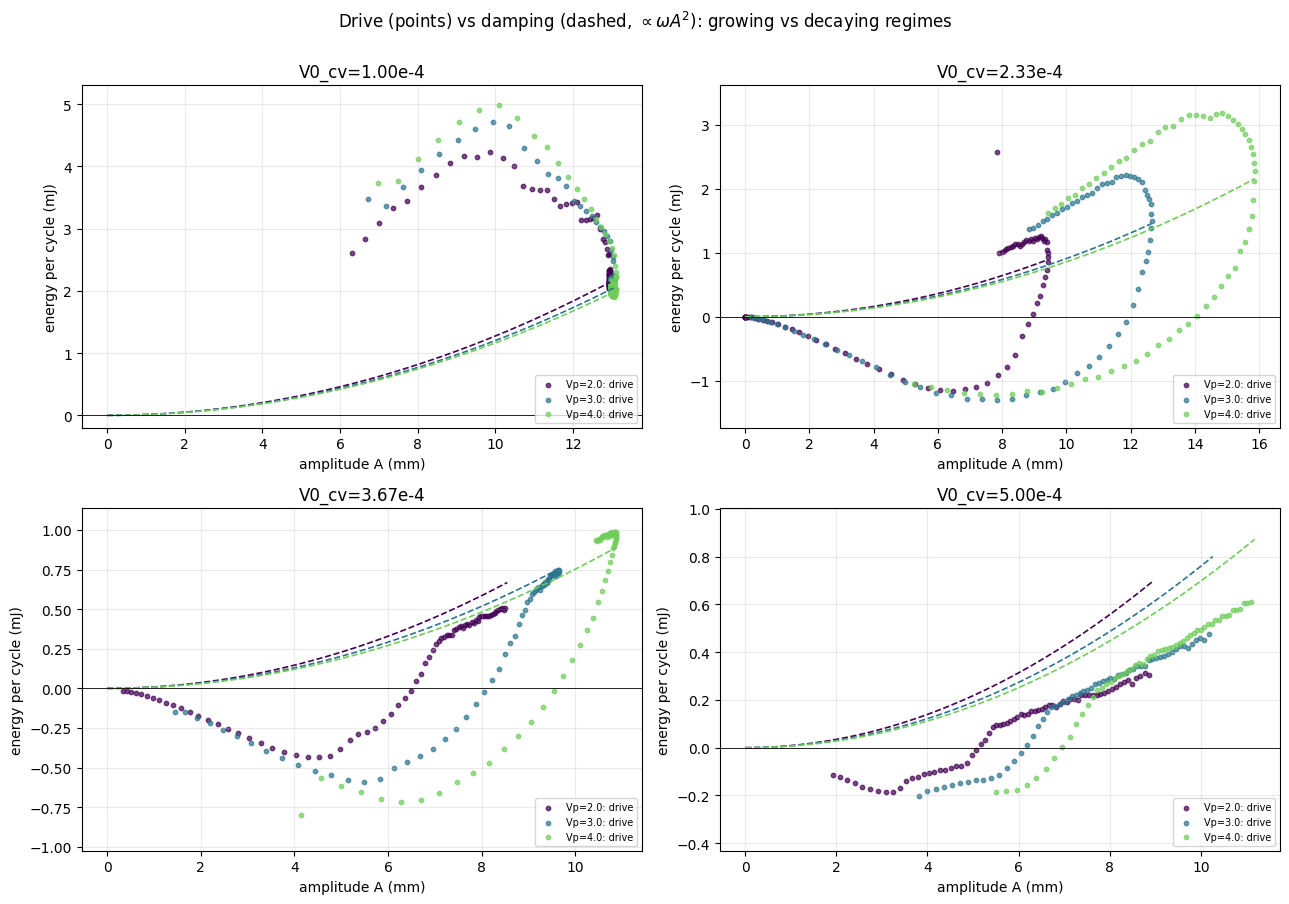

In [73]:
# Drive (scatter) vs damping (dashed parabola) across several V0_cv regimes.
# Growing regime gives a clean arc above damping; decaying regimes show the
# drive falling below damping, and a loop from the transient overshoot.
def plot_drive_damp_grid(V0_cv_values, V0_pass_values, t_span=(0.0, 0.8), n_eval=12_000):
    ncol = 2
    nrow = int(np.ceil(len(V0_cv_values) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(13, 4.5 * nrow))
    axes = np.atleast_1d(axes).ravel()
    colors = plt.cm.viridis(np.linspace(0, 0.78, len(V0_pass_values)))
    for ax, V0_cv_value in zip(axes, V0_cv_values):
        all_W = []
        damp_max = 0.0
        for color, Vp in zip(colors, V0_pass_values):
            sol = simulate_for_case(V0_cv_value, Vp, t_span, n_eval)
            t, x, v, M_cv, E_cv, V_cv, T_cv, P_cv, dV = solution_quantities(sol)
            P_pass = P0 * (Vp / (Vp - x * A_neck)) ** gamma
            drive_power = (P_cv - P_pass) * A_neck * v
            cycles = upward_zero_crossing_cycles(t, x)
            A = []
            W_drive = []
            for a, b in zip(cycles['t_start'], cycles['t_end']):
                m = (t >= a) & (t <= b)
                if m.sum() < 3:
                    continue
                A.append(0.5 * (np.nanmax(x[m]) - np.nanmin(x[m])))
                W_drive.append(np.trapezoid(drive_power[m], t[m]))
            A = np.array(A)
            W_drive = np.array(W_drive)
            omega = np.sqrt(gamma * P0 * A_neck ** 2 * (1.0 / V0_cv_value + 1.0 / Vp) / m_gas)
            A_line = np.linspace(0.0, A.max(), 120)
            W_damp_line = np.pi * b_gas * omega * A_line ** 2
            ax.scatter(A * 1e3, W_drive * 1e3, s=10, color=color, alpha=0.7, label=f'Vp={Vp * 1e4:.1f}: drive')
            ax.plot(A_line * 1e3, W_damp_line * 1e3, '--', color=color, lw=1.2)
            all_W.append(W_drive)
            damp_max = max(damp_max, W_damp_line.max())
            del sol
            gc.collect()
        all_W = np.concatenate(all_W) * 1e3
        lo = min(0.0, np.nanpercentile(all_W, 2))
        hi = max(np.nanpercentile(all_W, 98), damp_max * 1e3)
        ax.set_ylim(lo * 1.25 - 0.2, hi * 1.15)
        ax.axhline(0, color='k', lw=0.6)
        ax.set_title(f'V0_cv={V0_cv_value * 1e4:.2f}e-4')
        ax.set_xlabel('amplitude A (mm)')
        ax.set_ylabel('energy per cycle (mJ)')
        ax.grid(alpha=0.25)
        ax.legend(fontsize=7, loc='lower right')
    for ax in axes[len(V0_cv_values):]:
        ax.set_visible(False)
    fig.suptitle('Drive (points) vs damping (dashed, $\\propto\\omega A^2$): growing vs decaying regimes', y=1.0)
    plt.tight_layout()
    plt.show()


plot_drive_damp_grid([1.0e-4, 2.33e-4, 3.67e-4, 5.0e-4], [2.0e-4, 3.0e-4, 4.0e-4])


### The actual oscillation, for the same $V_{0,cv}$ and $V_{0,\text{pass}}$ choices

Raw displacement $x(t)$ for every case in the grid above, same colors (by $V_{0,\text{pass}}$), one panel per $V_{0,cv}$, with the amplitude envelope overlaid &mdash; centered on each cycle's *local* mean of $x$, not on $x=0$, since the equilibrium position itself can drift.

That drift turns out to matter: for $V_{0,cv}=1.0\times10^{-4}$ the envelope stays wide (a genuine sustained limit cycle, matching the drive/damping crossing above). In the other three panels the envelope **pinches to zero** &mdash; the oscillation truly dies, exactly as `cycle_amplitudes` reports &mdash; but the pinched band itself keeps **drifting**, settling 20&ndash;40&nbsp;mm away from $x=0$. The reed doesn't relax back to its starting position; the nonlinear, asymmetric reed flow lets it lock into a different static offset once the AC part of the motion is gone. So "decays" here means the oscillation collapses, not that the system returns to where it started.


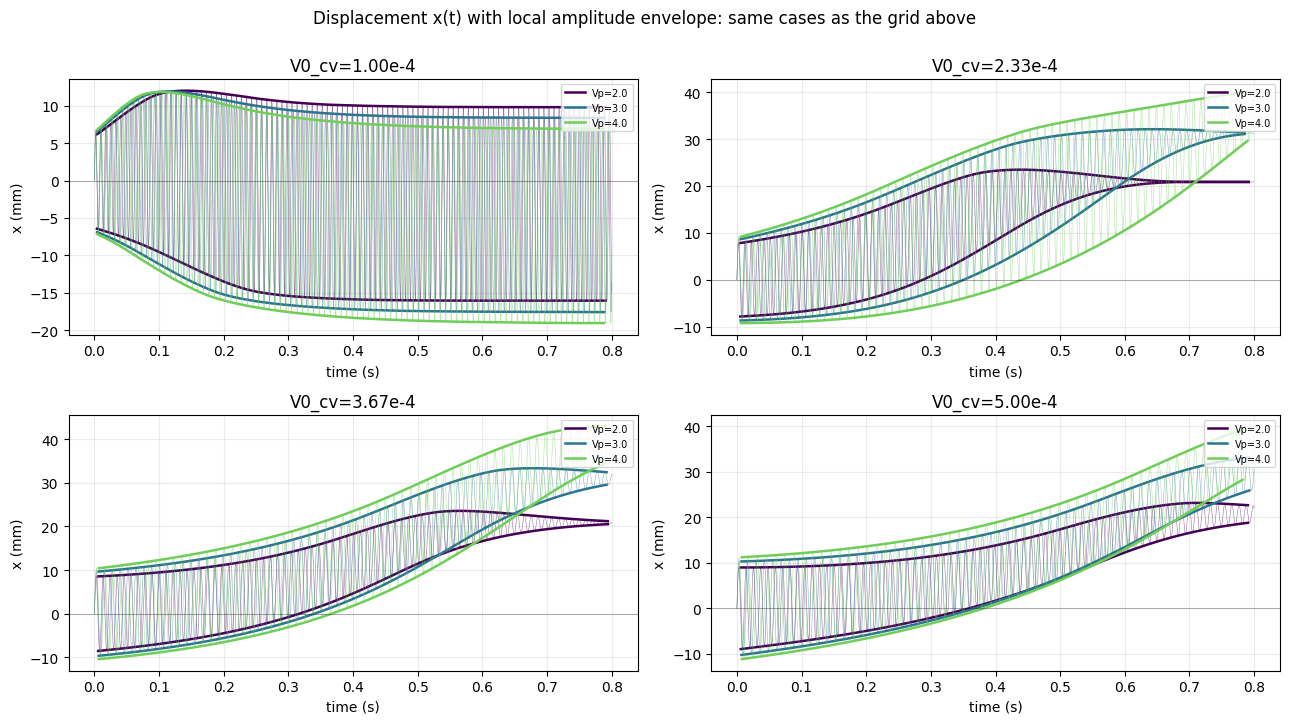

In [74]:
# Time-domain companion to the drive/damping grid: raw x(t) plus the per-cycle
# amplitude envelope, for the same (V0_cv, V0_pass) cases and colors. The envelope
# is centered on each cycle's local mean of x, not on 0 -- the reed can settle to a
# drifting equilibrium position even after the oscillation itself has died out, so a
# zero-centered band would visually separate from the raw trace in decaying cases.
def plot_oscillation_grid(V0_cv_values, V0_pass_values, t_span=(0.0, 0.8), n_eval=12_000):
    ncol = 2
    nrow = int(np.ceil(len(V0_cv_values) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(13, 3.6 * nrow), sharex=False)
    axes = np.atleast_1d(axes).ravel()
    colors = plt.cm.viridis(np.linspace(0, 0.78, len(V0_pass_values)))
    for ax, V0_cv_value in zip(axes, V0_cv_values):
        for color, Vp in zip(colors, V0_pass_values):
            sol = simulate_for_case(V0_cv_value, Vp, t_span, n_eval)
            t, x, v, M_cv, E_cv, V_cv, T_cv, P_cv, dV = solution_quantities(sol)
            ax.plot(t, x * 1e3, color=color, lw=0.4, alpha=0.55)

            cycles = upward_zero_crossing_cycles(t, x)
            t_mid, centers, amps = [], [], []
            for a, b in zip(cycles['t_start'], cycles['t_end']):
                seg = x[(t >= a) & (t <= b)]
                seg = seg[np.isfinite(seg)]
                if seg.size == 0:
                    continue
                t_mid.append(0.5 * (a + b))
                centers.append(0.5 * (seg.max() + seg.min()))
                amps.append(0.5 * (seg.max() - seg.min()))
            t_mid, centers, amps = np.array(t_mid), np.array(centers), np.array(amps)
            ax.plot(t_mid, (centers + amps) * 1e3, color=color, lw=1.8, label=f'Vp={Vp * 1e4:.1f}')
            ax.plot(t_mid, (centers - amps) * 1e3, color=color, lw=1.8)
            del sol
            gc.collect()
        ax.axhline(0.0, color='k', lw=0.5, alpha=0.4)
        ax.set_title(f'V0_cv={V0_cv_value * 1e4:.2f}e-4')
        ax.set_xlabel('time (s)')
        ax.set_ylabel('x (mm)')
        ax.grid(alpha=0.25)
        ax.legend(fontsize=7, loc='upper right')
    for ax in axes[len(V0_cv_values):]:
        ax.set_visible(False)
    fig.suptitle('Displacement x(t) with local amplitude envelope: same cases as the grid above', y=1.0)
    plt.tight_layout()
    plt.show()


plot_oscillation_grid([1.0e-4, 2.33e-4, 3.67e-4, 5.0e-4], [2.0e-4, 3.0e-4, 4.0e-4])


## Summary of findings

**Setup.** The gas slug in the neck obeys $m_{\text{gas}}\ddot x = (P_{cv}-P_{\text{pass}})A_{\text{neck}} - b_{\text{gas}}\dot x$, with the compression volume as an active spring driven through the reed and the passive volume as a return spring:
$$
k_{\text{pass}}=\frac{\gamma P_0 A_{\text{neck}}^2}{V_{0,\text{pass}}},\qquad
k_{\text{eff}}=\gamma P_0 A_{\text{neck}}^2\!\left(\frac{1}{V_{0,cv}}+\frac{1}{V_{0,\text{pass}}}\right),\qquad
\omega=\sqrt{\frac{k_{\text{eff}}}{m_{\text{gas}}}}.
$$

**1. Energy balance is quantitatively exact. This proves mechanical energy input CORRESPONDs TO LARGER AMPLITUDE** Per cycle, $\Delta E = W_{\text{drive}} - W_{\text{damp}} = \texttt{net\_mech\_per\_cycle}$. Since $E=\tfrac12 k_{\text{eff}}A^2$,
$$
\boxed{\;\texttt{net\_mech\_per\_cycle} = \tfrac12\,k_{\text{eff}}\,\Delta(A^2)\;}
$$
Fitting this line through the origin on real simulation data gave $R^2=0.998$, with the fitted slope recovering $k_{\text{eff}}$ to within 3% of the analytic value &mdash; the energy ledger reproduces the oscillator's actual stiffness, not just its sign.

**2. Growth mechanism: the reed acts as negative damping.** Because $P_{cv}$ depends on the state variable $E_{cv}$ (its own ODE, carrying memory via the reed's enthalpy flux) rather than being an instantaneous function of $x$, the net pressure force picks up a phase lag. Expanded to first order, that lag becomes a velocity term:
$$
(P_{cv}-P_{\text{pass}})A_{\text{neck}} \approx -k_{\text{eff}}x + \beta\dot x,\qquad \beta>0,
$$
$$
m_{\text{gas}}\ddot x + (b_{\text{gas}}-\beta)\dot x + k_{\text{eff}}x = 0
\;\Rightarrow\;
A(t)=A_0 e^{\sigma t},\quad
\boxed{\;\sigma=\dfrac{\beta-b_{\text{gas}}}{2m_{\text{gas}}}\;}.
$$
Regressing the simulated net force onto $x$ and $\dot x$ confirms this directly: $\beta=0.0147 > b_{\text{gas}}=0.005$ during growth ($R^2=0.993$), and $\beta\to b_{\text{gas}}=0.00497$ right at the limit cycle ($R^2=0.9999$) &mdash; drive exceeds damping while growing, and exactly matches it once amplitude saturates. A purely position-dependent force ($P_{\text{pass}}(x)$ alone) does zero net work over a cycle; all the pumping comes from this lag-induced $\beta\dot x$ term.

**3. Why a larger passive volume helps.** Increasing $V_{0,\text{pass}}$ softens $k_{\text{pass}}$ and lowers $\omega$, with two compounding effects:
- *Energy $\to$ initial amplitude:* the fixed kick energy $E_0=\tfrac12 m_{\text{gas}}v_0^2$ converts to $A_0=v_0/\omega$ &mdash; a softer spring turns the same energy into a bigger swing.
- *Damping $\to$ sustained amplitude:* $W_{\text{damp}}=\pi b_{\text{gas}}\omega A^2\propto\omega$, so a lower $\omega$ means less loss per cycle at a given $A$, and the limit cycle $A^*$ (where $W_{\text{drive}}(A^*)=W_{\text{damp}}(A^*)$) sits higher.

Measured across a $V_{0,\text{pass}}$ scan, $A_0=v_0/\omega$ matched the simulated first-cycle amplitude almost exactly, and the sustained amplitude rose from $0\to5.3$ mm as $V_{0,\text{pass}}$ increased &mdash; a dead oscillation becoming self-sustaining purely from softening the passive spring.

**4. Regime map across $V_{0,cv}$.** Sweeping $V_{0,cv}$ at fixed $V_{0,\text{pass}}$ produces three regimes, visible in both the drive-vs-damping and $x(t)$ figures above:
- **Growing** (small $V_{0,cv}$): drive cleanly exceeds damping, amplitude rises monotonically to a stable limit cycle.
- **Marginal/overshoot**: drive briefly exceeds damping, amplitude overshoots, then the trajectory loops back as damping catches up &mdash; no clean crossing, a genuinely transient phenomenon.
- **Decaying** (large $V_{0,cv}$): drive sits mostly below the damping parabola and the oscillation collapses to zero amplitude &mdash; but $x$ itself keeps drifting, settling 20&ndash;40 mm from its starting position. The nonlinear, asymmetric reed lets the piston lock into a new static offset rather than returning to $x=0$; "decay" here means the AC motion collapses, not that the system returns to where it started.

**5. Sign consistency holds everywhere tested.** Across the full $V_{0,cv}\times V_{0,\text{pass}}$ grid, $\operatorname{sign}(\Sigma\,\texttt{net\_mech\_per\_cycle})$ agreed with $\operatorname{sign}(\Delta A^2)$ in every case &mdash; the energy argument predicts growth vs. decay correctly, not just in the two illustrative cases but across the parameter space.


## Illustrating the negative-damping mechanism

The claim was $(P_{cv}-P_{\text{pass}})A_{\text{neck}}\approx -k_{\text{eff}}x+\beta\dot x$ with $\beta>0$, and that $\beta$ exceeds $b_{\text{gas}}$ while the oscillation grows, then settles to $\beta\approx b_{\text{gas}}$ at the limit cycle. Directly regressing net force on $x$ and $v$ shows $x$ alone already explains 99%+ of the force's variance &mdash; the $\beta\dot x$ term is a *small* correction on top of a dominant, somewhat nonlinear spring, so a naive residual-after-linear-fit plot is dominated by that nonlinearity rather than by $\beta$.

Two more robust checks below, both for the same growing case ($V_{0,cv}=1.0\times10^{-4}$, $V_{0,\text{pass}}=2.0\times10^{-4}$):

- **Left panel:** fit the force as a flexible (7th-order) function of $x$ alone for one representative growth-phase cycle, then plot what's left over against $v$. If the force were purely position-dependent, this residual would be structureless; instead it collapses onto a line through the origin ($R^2=0.98$), and its slope is $\beta$.
- **Right panel:** three *independent* ways to estimate $\beta$ &mdash; a multi-cycle windowed regression, a single-cycle regression, and a purely energetic estimate ($\beta=\text{loop area}/\oint v^2\,dt$, using that a pure spring force encloses zero area in the $(x,F)$ plane) &mdash; agree with each other in both phases, confirming $\beta>b_{\text{gas}}$ during growth and $\beta\approx b_{\text{gas}}$ at the limit cycle.


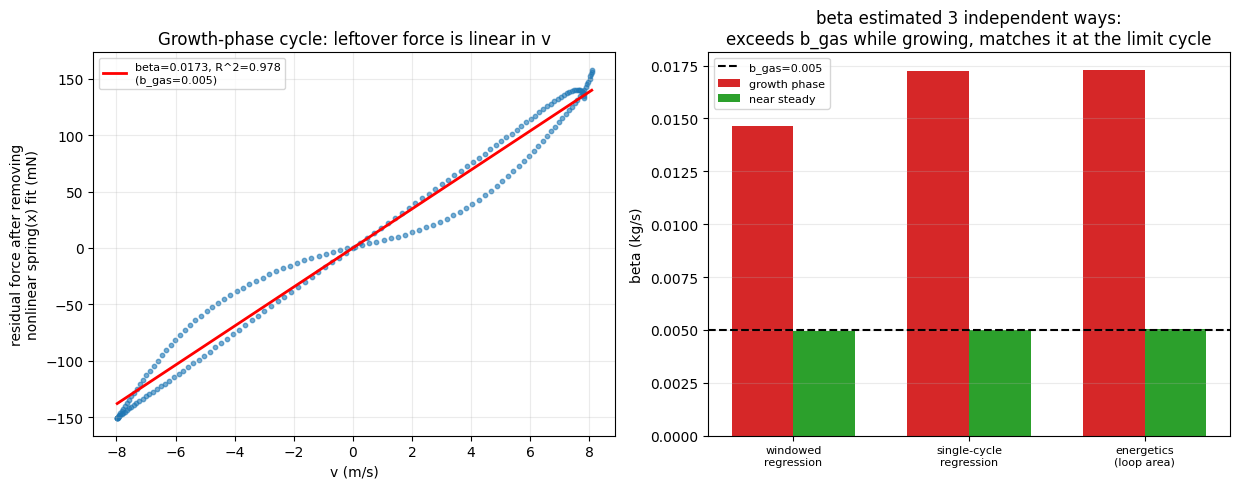

In [75]:
# Evidence for the negative-damping mechanism (P_cv-P_pass)A ~ -k_eff*x + beta*v:
# (1) after removing a flexible nonlinear fit of force vs x, the leftover force for a
#     growth-phase cycle collapses onto a line through the origin in v (the beta*v term);
# (2) three independent estimates of beta -- windowed regression, single-cycle regression,
#     and an energetic estimate from the (x, F) loop area -- agree, and show beta > b_gas
#     while growing vs beta ~= b_gas at the limit cycle.
def plot_negative_damping_evidence(V0_cv_value, V0_pass_value, t_span=(0.0, 0.6), n_eval=16_000,
                                    t_growth=0.08, t_steady=0.55,
                                    window_growth=(0.05, 0.20), window_steady=(0.45, 0.60)):
    sol = simulate_for_case(V0_cv_value, V0_pass_value, t_span, n_eval)
    t, x, v, M_cv, E_cv, V_cv, T_cv, P_cv, dV_cv_dt = solution_quantities(sol)
    V0_pass_used = getattr(sol, 'V0_pass', V0_pass_value)
    P_pass = P0 * (V0_pass_used / (V0_pass_used - x * A_neck)) ** gamma
    F = (P_cv - P_pass) * A_neck
    cycles = upward_zero_crossing_cycles(t, x)
    t_mid = 0.5 * (cycles['t_start'] + cycles['t_end'])

    def single_cycle_estimates(t_target):
        idx = np.argmin(np.abs(t_mid - t_target))
        a, b = cycles['t_start'][idx], cycles['t_end'][idx]
        sel = (t >= a) & (t <= b)
        xs, Fs, vs, ts = x[sel], F[sel], v[sel], t[sel]
        area = np.trapezoid(Fs, xs)                      # signed (x,F) loop area = net work this cycle
        beta_energy = area / np.trapezoid(vs ** 2, ts)    # since a pure spring encloses zero area
        xc = xs - xs.mean()
        coef, *_ = np.linalg.lstsq(np.column_stack([xc, vs]), Fs - Fs.mean(), rcond=None)
        poly = np.polyfit(xs, Fs, 7)                      # flexible nonlinear position-only fit
        resid = Fs - np.polyval(poly, xs)
        coef_r, *_ = np.linalg.lstsq(vs[:, None], resid, rcond=None)
        pred = coef_r[0] * vs
        R2 = 1.0 - np.sum((resid - pred) ** 2) / np.sum((resid - resid.mean()) ** 2)
        return dict(vs=vs, resid=resid, beta_poly=coef_r[0], R2=R2, beta_linreg=coef[1], beta_energy=beta_energy)

    def windowed_regression(t0, t1):
        sel = (t >= t0) & (t <= t1)
        xc = x[sel] - x[sel].mean()
        coef, *_ = np.linalg.lstsq(np.column_stack([xc, v[sel]]), F[sel] - F[sel].mean(), rcond=None)
        return coef[1]

    g = single_cycle_estimates(t_growth)
    s = single_cycle_estimates(t_steady)
    beta_win_growth = windowed_regression(*window_growth)
    beta_win_steady = windowed_regression(*window_steady)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 5.0))
    ax1.scatter(g['vs'], g['resid'] * 1e3, s=10, alpha=0.6, color='tab:blue')
    v_line = np.linspace(g['vs'].min(), g['vs'].max(), 50)
    ax1.plot(v_line, g['beta_poly'] * v_line * 1e3, 'r-', lw=2,
             label=f"beta={g['beta_poly']:.4f}, R^2={g['R2']:.3f}\n(b_gas={b_gas})")
    ax1.set_xlabel('v (m/s)')
    ax1.set_ylabel('residual force after removing\nnonlinear spring(x) fit (mN)')
    ax1.set_title('Growth-phase cycle: leftover force is linear in v')
    ax1.legend(fontsize=8)
    ax1.grid(alpha=0.25)

    methods = ['windowed\nregression', 'single-cycle\nregression', 'energetics\n(loop area)']
    growth_vals = [beta_win_growth, g['beta_linreg'], g['beta_energy']]
    steady_vals = [beta_win_steady, s['beta_linreg'], s['beta_energy']]
    xpos = np.arange(len(methods))
    width = 0.35
    ax2.bar(xpos - width / 2, growth_vals, width, color='tab:red', label='growth phase')
    ax2.bar(xpos + width / 2, steady_vals, width, color='tab:green', label='near steady')
    ax2.axhline(b_gas, color='k', ls='--', lw=1.5, label=f'b_gas={b_gas}')
    ax2.set_xticks(xpos)
    ax2.set_xticklabels(methods, fontsize=8)
    ax2.set_ylabel('beta (kg/s)')
    ax2.set_title('beta estimated 3 independent ways:\nexceeds b_gas while growing, matches it at the limit cycle')
    ax2.legend(fontsize=8)
    ax2.grid(alpha=0.25, axis='y')
    plt.tight_layout()
    plt.show()
    del sol
    gc.collect()


plot_negative_damping_evidence(1.0e-4, 2.0e-4)
